In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
from IPython.display import display

In [2]:
TASK = Path.cwd().parent
ROOT = TASK.parent
INPUT, OUTPUT = TASK/'input', TASK/'output'
CONFIG = json.loads((ROOT/'config.json').read_text())
Y, SEED = CONFIG['last_year'], CONFIG['seed']
REFERENCES = ['age_0','lag_3','lag_5']
LABELS = {'age_0':r'$\rho_S(R_0,R_t)$', 'lag_3':r'$\rho_S(R_{t-3},R_t)$', 'lag_5':r'$\rho_S(R_{t-5},R_t)$'}
COLORS = dict(zip(REFERENCES,sns.color_palette('colorblind',3)))
LINES = dict(zip(REFERENCES,['-','--','-.']))
MARKERS = dict(zip(REFERENCES,['o','s','^']))
sns.set_theme(style='ticks',context='paper',font_scale=1.15,
              rc={'pdf.fonttype':42,'ps.fonttype':42,'savefig.dpi':300})

In [ ]:
# annual ranks of the fixed complete-career DBLP cohort; zeros retain average ranks
ranks = pd.read_csv(INPUT/'rank_mixing.csv')
ranks = ranks.loc[ranks.source.eq('empirical_complete') & ranks.measure.eq('annual') & ranks.reference.isin(REFERENCES)].copy()
ranks = ranks.sort_values(['reference','age'])
ranks.to_csv(OUTPUT/'dblp_rank_mixing.csv',index=False)

In [ ]:
summary = ranks.groupby('reference',sort=False).agg(start_age=('age','min'),end_age=('age','max'), n=('n','first')).reindex(REFERENCES)
summary['terminal_rho'] = ranks.loc[ranks.age.eq(Y)].set_index('reference').rho
summary['measure'] = 'annual'
summary['cohort'] = 'DBLP complete careers'
summary.to_csv(OUTPUT/'dblp_rank_mixing_summary.csv')
display(summary)

,start_age,end_age,n,terminal_rho,measure,cohort
reference,,,,,,
age_0,0,20,510,0.187294,annual,DBLP complete careers
lag_3,3,20,510,0.653156,annual,DBLP complete careers
lag_5,5,20,510,0.582696,annual,DBLP complete careers


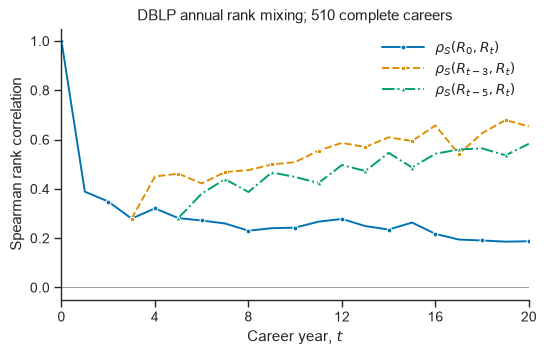

In [5]:
fig,ax = plt.subplots(figsize=(5.6,3.7))
for reference in REFERENCES:
    data = ranks.loc[ranks.reference.eq(reference)].sort_values('age')
    sns.lineplot(data=data,x='age',y='rho',ax=ax,color=COLORS[reference],linestyle=LINES[reference],
                 marker=MARKERS[reference],markersize=3.5,markevery=2,linewidth=1.4,
                 estimator=None,errorbar=None,label=LABELS[reference])
n = int(summary.n.iloc[0])
ax.axhline(0,color='.6',linewidth=.7,zorder=0)
ax.set(title=f'DBLP annual rank mixing; {n:,} complete careers',xlabel='Career year, $t$',
       ylabel='Spearman rank correlation',xlim=(0,Y),ylim=(-.05,1.05))
ax.xaxis.set_major_locator(MaxNLocator(integer=True,nbins=5))
ax.yaxis.set_major_locator(MaxNLocator(6))
ax.legend(frameon=False,loc='upper right',handlelength=3)
sns.despine(ax=ax)
fig.tight_layout()
for extension in ['pdf','png']:
    fig.savefig(OUTPUT/f'dblp_rank_mixing.{extension}',bbox_inches='tight',facecolor='white')
plt.show()
plt.close(fig)

In [6]:
caption = (
    r'\textbf{Annual productivity rank mixing in DBLP.} '
    f'The same {n:,} complete careers are used at every career year 0--{Y}. '
    r'$R_t$ denotes the cross-scholar rank of annual adjusted productivity at year $t$. '
    r'Curves report Spearman $\rho_S(R_0,R_t)$, $\rho_S(R_{t-3},R_t)$ and $\rho_S(R_{t-5},R_t)$, '
    r'starting at years 0, 3 and 5 respectively. Observed zeros are retained and ties receive average ranks. '
    r'These curves describe annual ranks; no rolling or cumulative productivity is used.'
)
(OUTPUT/'dblp_rank_mixing_caption.tex').write_text(caption+'\n')

476